# Análise exploratória — StockFlow (Silver → Gold análise)

Sprint 3. Segue a **seção 5 do Plano de Preparação de Dados** e o **requisito 3 de CC (EDA)**, com as análises estatísticas e probabilísticas pedidas pelo professor.

- Entrada (Silver): `data/silver/vendas_tratadas.parquet`.
- Saída (Gold — análise): `data/gold/vendas_analise.parquet`, a Silver mais as variáveis derivadas e o rótulo de ruptura.
- Registro: `docs/log_tratamento.md`, seção Silver → Gold.

One-hot, padronização e divisão treino/teste ficam para a Gold de modelos (Sprints 4 a 6), porque dependem do corte de treino.

**Os quatro princípios da EDA (Tukey)** guiam o notebook:

| Princípio | O que significa | Onde aparece |
|---|---|---|
| Revelação | Mostrar os dados em gráficos antes de resumir | Seções 4 a 9 |
| Resistência | Preferir medidas que não se deixam levar por poucos valores extremos (mediana, IQR) | Seções 3 e 11 |
| Reexpressão | Mudar a escala quando ela esconde o padrão (ex.: log) | Seção 4 |
| Resíduos | Tirar o efeito já explicado e olhar o que sobra | Seções 8, 10.1 e 11 |

## 1. Importações, leitura da Silver e estilo dos gráficos

In [1]:
import os
import subprocess
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

SILVER = "data/silver/vendas_tratadas.parquet"

# Funciona no Colab e localmente: se a Silver não estiver acessível, clona o repositório
if not os.path.exists(SILVER):
    if os.path.exists(os.path.join("..", SILVER)):
        os.chdir("..")
    else:
        subprocess.run(["git", "clone", "https://github.com/juliamariateixeiraa/StockFlow.git"], check=True)
        os.chdir("StockFlow")

df = pd.read_parquet(SILVER)
print(df.shape)

(76000, 21)


In [2]:
# Paleta categórica em ordem fixa (testada para daltonismo) e eixos discretos
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
AZUL, LARANJA, CINZA = CORES[0], CORES[1], "#898781"
DIVERGENTE = mpl.colors.LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#ef9a8f", "#b8302f"])

mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=CORES), "lines.linewidth": 2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 100, "figure.figsize": (10, 4),
})

def media_ic(serie):
    """Média e meia-largura do intervalo de 95% (aproximação normal)."""
    return serie.mean(), 1.96 * serie.std() / np.sqrt(len(serie))

def barras_media(ax, base, grupo, alvo="demanda", ordem=None, titulo=""):
    tab = base.groupby(grupo)[alvo].agg(["mean", "std", "count"])
    if ordem is not None:
        tab = tab.loc[ordem]
    ic = 1.96 * tab["std"] / np.sqrt(tab["count"])
    ax.bar(tab.index.astype(str), tab["mean"], yerr=ic, color=AZUL, width=0.6, capsize=3,
           error_kw={"ecolor": "#52514e", "elinewidth": 1})
    for x, v in zip(tab.index.astype(str), tab["mean"]):
        ax.annotate(f"{v:.1f}", (x, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, color="#52514e")
    ax.set_title(titulo)
    ax.grid(axis="x", visible=False)
    return tab

## 2. Variáveis derivadas (Gold — análise)

Seção 5 do plano. Todas as variáveis que usam histórico são calculadas **por loja × produto, em ordem de data**: o log de tratamento (etapa 7c) mostrou que o mesmo `produto_id` tem categoria diferente em cada loja, então o item de verdade é o par.

### 2.1 Calendário: dia da semana, mês, ano e fim de semana

In [3]:
item = ["loja_id", "produto_id"]
df = df.sort_values(item + ["data"]).reset_index(drop=True)

df["dia_semana"] = df["data"].dt.dayofweek.astype("int64")   # 0 = segunda, 6 = domingo
df["mes"] = df["data"].dt.month.astype("int64")
df["ano"] = df["data"].dt.year.astype("int64")
df["fim_de_semana"] = (df["dia_semana"] >= 5).astype("int64")

# Cada item precisa ter uma linha por dia, sem buracos, para as defasagens fazerem sentido
passo = df.groupby(item)["data"].diff().dropna()
print("Intervalo entre linhas do mesmo item:", passo.unique())

Intervalo entre linhas do mesmo item: <TimedeltaArray>
['1 days']
Length: 1, dtype: timedelta64[us]


### 2.2 Venda dos dias anteriores e média móvel

- `_lag1` e `_lag7`: valor de 1 e 7 dias antes.
- `_mm7`: média dos **7 dias anteriores**, sem incluir o próprio dia. Assim nenhuma dessas colunas usa informação que só se conhece depois do dia acabar (pesquisa de métodos, seção 3).

O plano fala em "venda dos dias anteriores". As defasagens são calculadas para `unidades_vendidas` e para `demanda`, porque o alvo da regressão só é fechado na Sprint 4 e a pesquisa usou a demanda nas previsões de referência. Os primeiros 7 dias de cada item ficam sem valor (não há histórico).

In [4]:
g = df.groupby(item)
for col, nome in [("unidades_vendidas", "venda"), ("demanda", "demanda")]:
    df[f"{nome}_lag1"] = g[col].shift(1)
    df[f"{nome}_lag7"] = g[col].shift(7)
    df[f"{nome}_mm7"] = g[col].transform(lambda s: s.shift(1).rolling(7, min_periods=7).mean())

# Conferência em um item: a média móvel do dia 8 é a média dos dias 1 a 7
ex = df[(df["loja_id"] == "S001") & (df["produto_id"] == "P0001")].head(8)
print("Média dos 7 primeiros dias:", ex["unidades_vendidas"].head(7).mean(), "| venda_mm7 no 8º dia:", ex["venda_mm7"].iloc[7])
ex[["data", "unidades_vendidas", "venda_lag1", "venda_lag7", "venda_mm7"]]

Média dos 7 primeiros dias: 96.57142857142857 | venda_mm7 no 8º dia: 96.57142857142857


,data,unidades_vendidas,venda_lag1,venda_lag7,venda_mm7
0,2022-01-01,102,NaN,NaN,NaN
1,2022-01-02,71,102.0,NaN,NaN
2,2022-01-03,142,71.0,NaN,NaN
3,2022-01-04,42,142.0,NaN,NaN
4,2022-01-05,129,42.0,NaN,NaN
5,2022-01-06,98,129.0,NaN,NaN
6,2022-01-07,92,98.0,NaN,NaN
7,2022-01-08,96,92.0,102.0,96.571429


### 2.3 Preço: diferença para o concorrente e preço com desconto

In [5]:
df["dif_preco_concorrente"] = (df["preco"] - df["preco_concorrente"]).round(2)
df["preco_com_desconto"] = (df["preco"] * (1 - df["desconto"] / 100)).round(2)

print("Correlação preço × preço do concorrente:", round(df["preco"].corr(df["preco_concorrente"]), 3))
print("Correlação preço × diferença para o concorrente:", round(df["preco"].corr(df["dif_preco_concorrente"]), 3))
df[["preco", "preco_concorrente", "dif_preco_concorrente", "desconto", "preco_com_desconto"]].describe().round(2).T

Correlação preço × preço do concorrente: 0.977
Correlação preço × diferença para o concorrente: -0.069


,count,mean,std,min,25%,50%,75%,max
preco,76000.0,67.73,39.38,4.74,32.00,64.50,95.83,228.03
preco_concorrente,76000.0,69.45,40.94,4.29,32.62,65.70,97.93,261.22
dif_preco_concorrente,76000.0,-1.73,8.82,-45.38,-7.23,0.03,3.75,33.09
desconto,76000.0,9.09,7.48,0.00,5.00,10.00,10.00,25.00
preco_com_desconto,76000.0,61.85,36.98,3.79,29.02,58.18,87.12,228.03


**Interpretação:** o preço e o preço do concorrente têm correlação de 0,98: as duas colunas dizem quase a mesma coisa. A diferença entre elas quase não se relaciona com o preço (−0,07), então traz uma informação nova sem repetir a do preço, como o plano previa. A mediana da diferença é praticamente zero (R$ 0,03): metade dos dias o produto está mais caro que o concorrente, metade mais barato. O preço com desconto fica, em média, R$ 5,88 abaixo do preço de tabela.

### 2.4 Cobertura de estoque

Quantos dias o estoque dura no ritmo de venda recente: `estoque ÷ venda_mm7`. Usa a média de **venda** (é a venda que consome o estoque) dos 7 dias anteriores. Como o estoque registrado é o do início do dia (log, etapa 7b), a cobertura é conhecida antes do dia começar e pode alimentar o alerta.

In [6]:
df["cobertura_estoque"] = (df["estoque"] / df["venda_mm7"].replace(0, np.nan)).round(2)
print("Linhas sem cobertura (primeiros 7 dias de cada item):", df["cobertura_estoque"].isna().sum())
df["cobertura_estoque"].describe(percentiles=[.1, .25, .5, .75, .9]).round(2)

Linhas sem cobertura (primeiros 7 dias de cada item): 700


count    75300.00
mean         3.56
std          2.70
min          0.00
10%          1.14
25%          1.64
50%          2.78
75%          4.78
90%          7.01
max         55.55
Name: cobertura_estoque, dtype: float64

### 2.5 Rótulo de ruptura

O plano aceita duas regras e o log deixou a escolha para o grupo. **Decisão: `ruptura = 1` quando venda ≥ estoque OU demanda > estoque.**

In [7]:
vendeu_tudo = df["unidades_vendidas"] >= df["estoque"]
faltou = df["demanda"] > df["estoque"]

regras = pd.DataFrame({
    "dias": [vendeu_tudo.sum(), faltou.sum(), (vendeu_tudo & ~faltou).sum(), (faltou & ~vendeu_tudo).sum(), (vendeu_tudo | faltou).sum()],
}, index=["venda ≥ estoque", "demanda > estoque", "só venda ≥ estoque", "só demanda > estoque", "uma das duas (regra adotada)"])
regras["% das linhas"] = (regras["dias"] / len(df) * 100).round(1)

df["ruptura"] = (vendeu_tudo | faltou).astype("int64")
regras

,dias,% das linhas
venda ≥ estoque,8654,11.4
demanda > estoque,10394,13.7
só venda ≥ estoque,806,1.1
só demanda > estoque,2546,3.4
uma das duas (regra adotada),11200,14.7


In [8]:
# Os 806 dias que só a regra da venda pega: estoque baixo e demanda registrada abaixo dele
so_venda = df[vendeu_tudo & ~faltou]
so_venda[["estoque", "unidades_vendidas", "demanda", "flag_venda_maior_demanda"]].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
estoque,806.0,132.1,39.7,28.0,107.0,127.0,154.0,320.0
unidades_vendidas,806.0,132.1,39.7,28.0,107.0,127.0,154.0,320.0
demanda,806.0,123.8,36.8,25.0,100.0,118.5,144.0,284.0
flag_venda_maior_demanda,806.0,0.9,0.3,0.0,1.0,1.0,1.0,1.0


**Interpretação e decisão:** a regra adotada marca 11.200 dias (14,7%). As duas condições juntas se justificam assim:

- **venda ≥ estoque** é a evidência direta: o estoque zerou no dia. É também a única regra que funciona com a planilha real da Renata, que tem venda e estoque, mas não tem demanda.
- **demanda > estoque** pega os dias em que faltou produto para o que o cliente queria, mesmo sem o estoque zerar no registro.
- Os 806 dias que só a primeira regra pega têm o estoque zerado (venda = estoque) e, em 90% deles, a `demanda` registrada abaixo da venda, que é a inconsistência apontada no log (etapa 6f). Usar só "demanda > estoque" deixaria de fora rupturas que aconteceram, por um erro da coluna `demanda`.
- A pesquisa de métodos (seção 4) pede para priorizar o recall do alerta: deixar de avisar uma ruptura custa mais para a Renata que um alarme falso. A regra mais abrangente vai na mesma direção.

Como o estoque registrado é o do início do dia (log, etapa 7b), a ruptura é um rótulo **do próprio dia**. Na classificação (Sprint 4), as variáveis de entrada precisam ser conhecidas antes do dia: estoque do início do dia, cobertura, defasagens e calendário.

In [9]:
novas = ["dia_semana", "mes", "ano", "fim_de_semana", "venda_lag1", "venda_lag7", "venda_mm7",
         "demanda_lag1", "demanda_lag7", "demanda_mm7", "dif_preco_concorrente", "preco_com_desconto",
         "cobertura_estoque", "ruptura"]
print("Colunas novas:", len(novas), "| Base:", df.shape)
df[novas].isna().sum().to_frame("nulos").T

Colunas novas: 14 | Base: (76000, 35)


,dia_semana,mes,ano,fim_de_semana,venda_lag1,venda_lag7,venda_mm7,demanda_lag1,demanda_lag7,demanda_mm7,dif_preco_concorrente,preco_com_desconto,cobertura_estoque,ruptura
nulos,0,0,0,0,100,700,700,100,700,700,0,0,700,0


## 3. Estatística descritiva (resistência)

Média e mediana lado a lado: quando ficam longe uma da outra, poucos valores extremos estão puxando a média. O coeficiente de variação (CV = desvio ÷ média) compara a oscilação entre grupos com níveis diferentes.

In [10]:
num = ["demanda", "unidades_vendidas", "estoque", "unidades_pedidas", "preco_com_desconto",
       "dif_preco_concorrente", "desconto", "cobertura_estoque"]
desc = df[num].describe().T
desc["assimetria"] = df[num].skew()
desc["curtose"] = df[num].kurt()
desc["cv"] = desc["std"] / desc["mean"]
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,assimetria,curtose,cv
demanda,76000.0,104.32,46.96,4.00,71.00,100.00,133.00,430.00,0.61,0.67,0.45
unidades_vendidas,76000.0,88.83,43.99,0.00,58.00,84.00,114.00,426.00,0.79,1.25,0.50
estoque,76000.0,301.06,226.51,0.00,136.00,227.00,408.00,2267.00,1.59,3.37,0.75
unidades_pedidas,76000.0,89.09,162.40,0.00,0.00,0.00,121.00,1616.00,2.52,7.31,1.82
preco_com_desconto,76000.0,61.85,36.98,3.79,29.02,58.18,87.12,228.03,0.59,-0.25,0.60
dif_preco_concorrente,76000.0,-1.73,8.82,-45.38,-7.23,0.03,3.75,33.09,-0.34,0.27,-5.10
desconto,76000.0,9.09,7.48,0.00,5.00,10.00,10.00,25.00,0.64,-0.41,0.82
cobertura_estoque,75300.0,3.56,2.70,0.00,1.64,2.78,4.78,55.55,2.39,14.67,0.76


**Interpretação:**

- **Demanda:** média 104,3 e mediana 100. A média um pouco acima da mediana e a assimetria de 0,61 mostram uma cauda moderada à direita: alguns dias de demanda alta, mas nada extremo.
- **Venda:** fica em média 15 unidades abaixo da demanda e é mais assimétrica (0,79), efeito da venda censurada: nos dias de ruptura a venda para no estoque.
- **Estoque, pedidos e cobertura** são as variáveis mais assimétricas (1,6, 2,5 e 2,4). Os pedidos têm 62% de zeros (dias sem pedido), por isso a média (89) não representa um dia típico (mediana 0). Nessas colunas a mediana e o IQR descrevem melhor o dia comum que a média e o desvio (princípio da resistência).
- **Cobertura:** metade dos dias tem estoque para menos de 2,8 dias de venda, e 10% para menos de 1,1 dia.

In [11]:
def resumo(base, grupo):
    t = base.groupby(grupo).agg(
        demanda_media=("demanda", "mean"), demanda_mediana=("demanda", "median"),
        desvio=("demanda", "std"), assimetria=("demanda", "skew"),
        venda_media=("unidades_vendidas", "mean"), ruptura_pct=("ruptura", "mean"),
    )
    t["cv"] = t["desvio"] / t["demanda_media"]
    t["ruptura_pct"] *= 100
    return t.round(2)

resumo(df, "categoria")

,demanda_media,demanda_mediana,desvio,assimetria,venda_media,ruptura_pct,cv
categoria,,,,,,,
Clothing,112.62,109.0,41.02,0.55,94.64,20.86,0.36
Electronics,97.48,95.0,40.56,0.51,83.04,14.99,0.42
Furniture,73.58,72.0,32.34,0.41,64.38,8.52,0.44
Groceries,120.98,116.0,48.36,0.61,102.87,14.43,0.40
Toys,92.61,92.0,46.17,0.32,78.45,16.40,0.50


In [12]:
resumo(df, "regiao")

,demanda_media,demanda_mediana,desvio,assimetria,venda_media,ruptura_pct,cv
regiao,,,,,,,
East,106.47,102.0,47.42,0.62,90.50,14.34,0.45
North,103.77,100.0,47.74,0.61,88.19,15.71,0.46
South,106.94,103.0,45.61,0.53,91.19,13.80,0.43
West,100.63,96.0,45.99,0.68,86.07,14.12,0.46


In [13]:
# Uma linha por item (loja × produto): quanto os itens diferem entre si
por_item = resumo(df, item)
por_item.describe().round(2).T[["mean", "min", "25%", "50%", "75%", "max"]]

,mean,min,25%,50%,75%,max
demanda_media,104.32,71.68,92.48,109.46,120.90,124.64
demanda_mediana,101.26,70.00,91.00,106.00,116.12,122.00
desvio,42.90,31.00,38.42,45.88,47.97,52.23
assimetria,0.49,0.17,0.37,0.49,0.60,0.88
venda_media,88.83,61.80,77.10,93.26,102.90,108.84
ruptura_pct,14.74,2.63,5.39,9.67,21.68,47.63
cv,0.42,0.35,0.39,0.41,0.44,0.52


**Interpretação:**

- **Categoria separa bem o nível da demanda:** Groceries tem a maior (média 121) e Furniture a menor (73,6). A ruptura também muda muito: 20,9% dos dias em Clothing contra 8,5% em Furniture.
- **Região quase não diferencia:** a demanda vai de 100,6 a 106,9 e a ruptura de 13,8% a 15,7%. Isso confirma o que o plano previa (seção 2): região serve como filtro do dashboard, mas acrescenta pouco à análise da loja única da Renata.
- **Os itens diferem mais no nível que na oscilação:** a demanda média vai de 72 a 125 unidades, mas o CV fica entre 0,35 e 0,52 em todos. Já a ruptura vai de **2,6% a 47,6%** dos dias conforme o item, uma diferença enorme que a seção 9 investiga.

## 4. Distribuições (revelação e reexpressão)

O plano prevê aplicar log(1 + x) no alvo se a distribuição for muito assimétrica. Aqui se decide se é preciso.

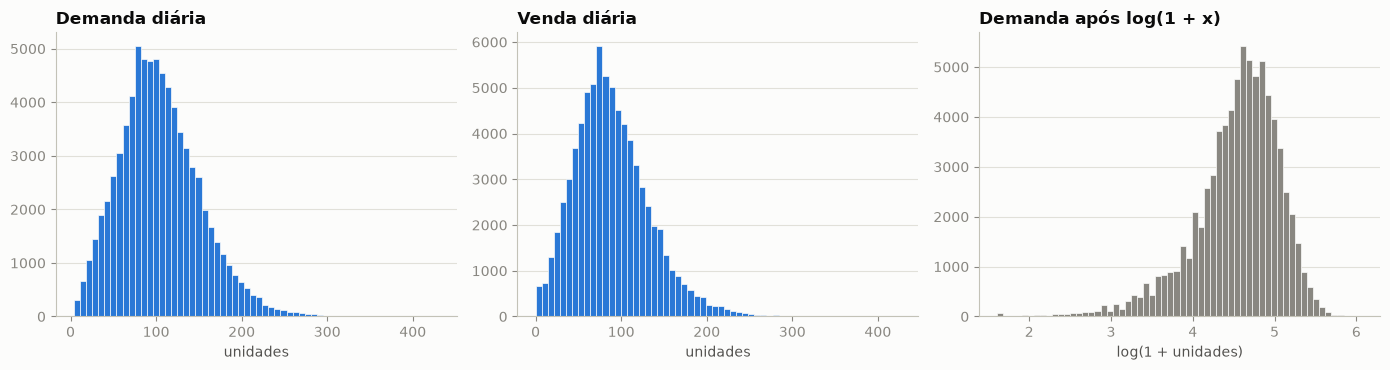

Assimetria — demanda: 0.61 | venda: 0.79 | log(1 + demanda): -1.1


In [14]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
axs[0].hist(df["demanda"], bins=60, color=AZUL, edgecolor="#fcfcfb", linewidth=0.5)
axs[0].set_title("Demanda diária")
axs[0].set_xlabel("unidades")
axs[1].hist(df["unidades_vendidas"], bins=60, color=AZUL, edgecolor="#fcfcfb", linewidth=0.5)
axs[1].set_title("Venda diária")
axs[1].set_xlabel("unidades")
axs[2].hist(np.log1p(df["demanda"]), bins=60, color=CINZA, edgecolor="#fcfcfb", linewidth=0.5)
axs[2].set_title("Demanda após log(1 + x)")
axs[2].set_xlabel("log(1 + unidades)")
for ax in axs:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print("Assimetria — demanda:", round(df["demanda"].skew(), 2),
      "| venda:", round(df["unidades_vendidas"].skew(), 2),
      "| log(1 + demanda):", round(np.log1p(df["demanda"]).skew(), 2))

**Interpretação (reexpressão):** a demanda tem forma de sino com cauda moderada à direita (assimetria 0,61). O log(1 + x) **piora** a forma: inverte a cauda para a esquerda (assimetria −1,1), porque comprime os valores altos e estica os poucos dias de demanda muito baixa. **Decisão: não aplicar log no alvo.** O plano só pede o log se a distribuição for muito assimétrica, e 0,61 está abaixo de 1, o limite usual para assimetria forte. A venda é parecida, com mais dias perto de zero (os dias sem estoque).

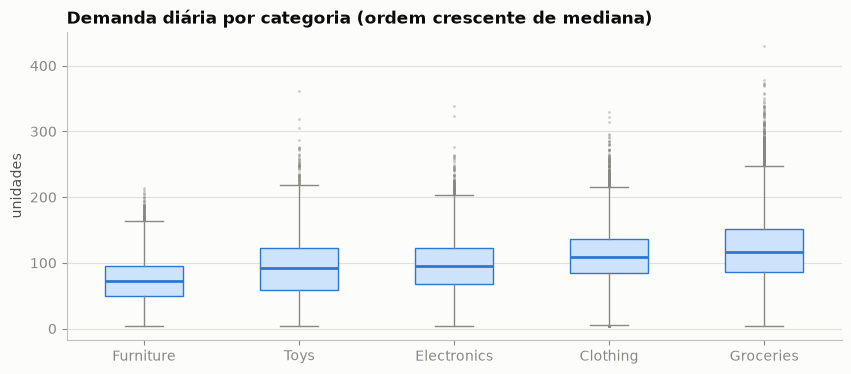

In [15]:
ordem_cat = df.groupby("categoria")["demanda"].median().sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([df.loc[df["categoria"] == c, "demanda"] for c in ordem_cat], widths=0.5,
           patch_artist=True, boxprops={"facecolor": "#cde2fb", "edgecolor": AZUL},
           medianprops={"color": AZUL, "linewidth": 2}, whiskerprops={"color": CINZA}, capprops={"color": CINZA},
           flierprops={"marker": "o", "markersize": 2, "markerfacecolor": CINZA, "markeredgecolor": "none", "alpha": 0.4})
ax.set_xticks(range(1, len(ordem_cat) + 1), ordem_cat)
ax.set_title("Demanda diária por categoria (ordem crescente de mediana)")
ax.set_ylabel("unidades")
ax.grid(axis="x", visible=False)
plt.show()

**Interpretação:** as cinco categorias têm a mesma forma, deslocada para cima ou para baixo: Furniture vende menos, Groceries mais. Os pontos acima dos bigodes aparecem em todas as categorias e só do lado de cima: são dias de demanda alta (a seção 11 mostra que vêm da promoção), não erros. Groceries tem mais pontos porque tem mais itens (30.400 linhas, 40% da base).

## 5. Padrões no tempo

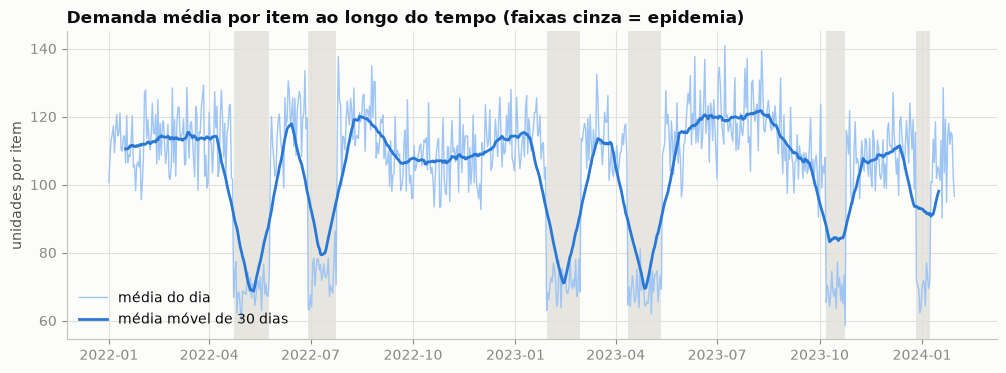

In [16]:
diario = df.groupby("data").agg(demanda=("demanda", "mean"), epidemia=("epidemia", "max"), ruptura=("ruptura", "mean"))

fig, ax = plt.subplots(figsize=(12, 4))
# Faixas cinza nos blocos de epidemia
blocos = (diario["epidemia"].diff() != 0).cumsum()
for _, b in diario[diario["epidemia"] == 1].groupby(blocos[diario["epidemia"] == 1]):
    ax.axvspan(b.index.min(), b.index.max(), color="#e1e0d9", alpha=0.8, lw=0)
ax.plot(diario.index, diario["demanda"], color="#9ec5f4", linewidth=1, label="média do dia")
ax.plot(diario.index, diario["demanda"].rolling(30, center=True).mean(), color=AZUL, label="média móvel de 30 dias")
ax.set_title("Demanda média por item ao longo do tempo (faixas cinza = epidemia)")
ax.set_ylabel("unidades por item")
ax.legend(loc="lower left", frameon=False)
plt.show()

**Interpretação:**

- **A epidemia é o padrão mais forte da série:** em cada um dos 6 blocos, a demanda cai de 105–120 para perto de 70 unidades por item e volta ao nível anterior quando o bloco termina.
- **Fora da epidemia,** a demanda sobe no meio do ano (junho a agosto, perto de 120) e fica mais baixa no outono (perto de 107). O padrão se repete em 2022 e 2023.
- **Não há tendência de crescimento ou queda** entre 2022 e 2024.
- A média do dia oscila bastante em torno da média móvel. É o "ruído" que a pesquisa de métodos já tinha visto: a demanda varia muito de um dia para o outro em torno de um nível.

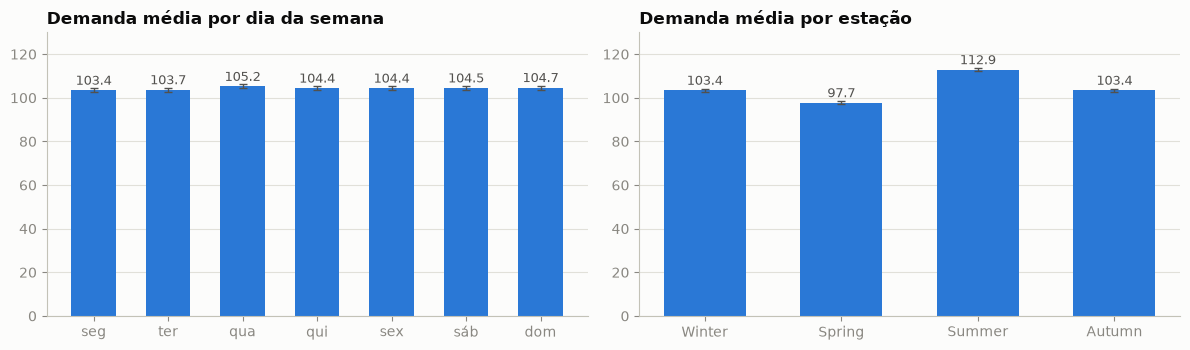

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
nomes_dia = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
t = barras_media(axs[0], df, "dia_semana", titulo="Demanda média por dia da semana")
axs[0].set_xticks(range(7), nomes_dia)
axs[0].set_ylim(0, 130)
barras_media(axs[1], df, "estacao", ordem=["Winter", "Spring", "Summer", "Autumn"], titulo="Demanda média por estação")
axs[1].set_ylim(0, 130)
plt.tight_layout()
plt.show()

**Interpretação:** a demanda é praticamente a mesma em todos os dias da semana (103 a 105). **O dia da semana e o fim de semana não ajudam a prever a demanda** e o teste de hipótese da seção 10.3 confirma isso. Já a estação muda o nível: o verão é cerca de 15% maior que a primavera. Parte dessa diferença vem da epidemia, que caiu mais na primavera; a seção 6 separa os dois efeitos.

## 6. Estação ou mês: qual manter

O plano pede para manter só uma das duas (seção 5). A comparação usa o η² (eta ao quadrado): a parte da variação da demanda explicada pela variável. Como a epidemia ocupa meses diferentes em cada ano, a comparação é feita também sem os dias de epidemia.

In [18]:
def eta2(y, grupo):
    """Parte da variância de y explicada pelo grupo (0 a 1)."""
    media = y.mean()
    entre = y.groupby(grupo).apply(lambda v: len(v) * (v.mean() - media) ** 2).sum()
    return entre / ((y - media) ** 2).sum()

sem_epi = df[df["epidemia"] == 0]
pd.DataFrame({
    "base toda": [eta2(df["demanda"], df["mes"]), eta2(df["demanda"], df["estacao"])],
    "sem epidemia": [eta2(sem_epi["demanda"], sem_epi["mes"]), eta2(sem_epi["demanda"], sem_epi["estacao"])],
}, index=["mês (12 classes)", "estação (4 classes)"]).round(4)

,base toda,sem epidemia
mês (12 classes),0.0438,0.0103
estação (4 classes),0.0130,0.0099


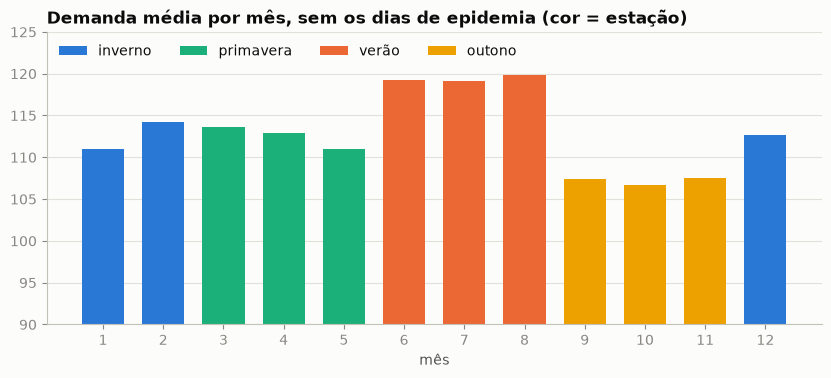

ano,2022,2023,2024
mes,,,
1,0.0,10.0,27.0
2,0.0,100.0,NaN
3,0.0,0.0,NaN
4,27.0,63.0,NaN
5,81.0,39.0,NaN
6,7.0,0.0,NaN
7,77.0,0.0,NaN
8,0.0,0.0,NaN
9,0.0,0.0,NaN


In [19]:
cor_estacao = {"Winter": CORES[0], "Spring": CORES[2], "Summer": CORES[1], "Autumn": CORES[3]}
nomes_estacao = {"Winter": "inverno", "Spring": "primavera", "Summer": "verão", "Autumn": "outono"}
mensal = sem_epi.groupby(["mes", "estacao"])["demanda"].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 3.8))
for est in ["Winter", "Spring", "Summer", "Autumn"]:
    sub = mensal[mensal["estacao"] == est]
    ax.bar(sub["mes"], sub["demanda"], color=cor_estacao[est], width=0.7, label=nomes_estacao[est])
ax.set_xticks(range(1, 13))
ax.set_ylim(90, 125)
ax.set_title("Demanda média por mês, sem os dias de epidemia (cor = estação)")
ax.set_xlabel("mês")
ax.legend(ncol=4, frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
plt.show()

# Pesquisa de epidemia por mês: explica a variação extra do mês na base toda
df.pivot_table(index="mes", columns="ano", values="epidemia", aggfunc="mean").mul(100).round(0)

**Interpretação e decisão: manter `estacao` nos modelos e deixar `mes` só para análise e filtros.**

- Na base toda, o mês parece explicar mais que a estação (η² de 0,044 contra 0,013). Mas a tabela de epidemia mostra o motivo: os blocos de epidemia caíram em meses específicos (maio e julho de 2022, fevereiro e outubro de 2023). O mês está "aprendendo" quando houve epidemia, e não um padrão que se repete.
- **Sem os dias de epidemia, os dois explicam o mesmo** (0,0103 e 0,0099). No gráfico, os meses de uma mesma estação ficam quase iguais: verão de 119,1 a 119,8, outono de 106,6 a 107,5.
- A estação dá o mesmo resultado com 4 classes em vez de 12. No one-hot, isso significa 3 colunas em vez de 11, menos risco de o modelo decorar ruído e coeficientes mais fáceis de explicar para a Renata.

## 7. Fatores externos: promoção, clima, epidemia e desconto

Barras com a demanda média e o intervalo de 95% da média.

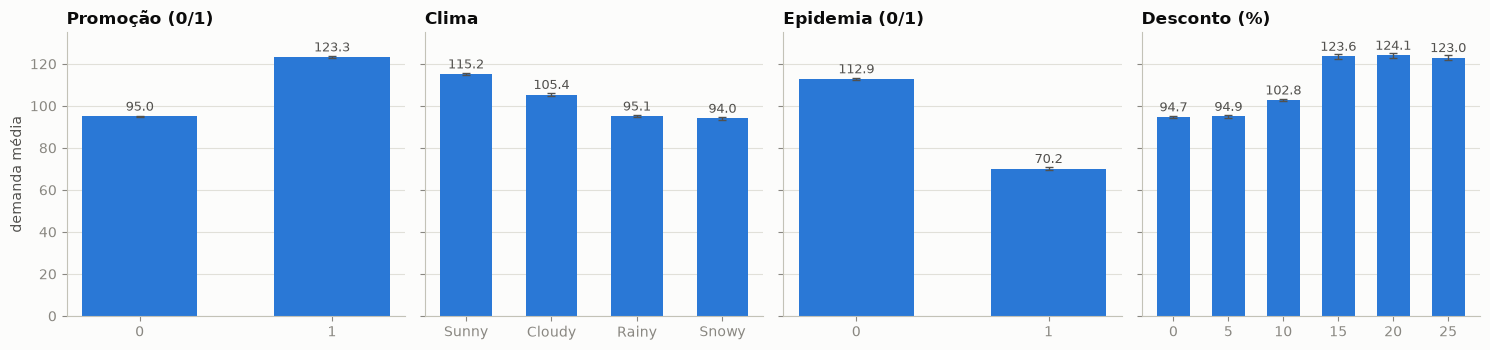

In [20]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
barras_media(axs[0], df, "promocao", titulo="Promoção (0/1)")
barras_media(axs[1], df, "clima", ordem=["Sunny", "Cloudy", "Rainy", "Snowy"], titulo="Clima")
barras_media(axs[2], df, "epidemia", titulo="Epidemia (0/1)")
barras_media(axs[3], df, "desconto", titulo="Desconto (%)")
axs[0].set_ylabel("demanda média")
axs[0].set_ylim(0, 135)
plt.tight_layout()
plt.show()

In [21]:
# Promoção e desconto andam juntos (log de tratamento, etapa 7c). Separando os dois:
df.pivot_table(index="desconto", columns="promocao", values="demanda", aggfunc="mean").round(1)

promocao,0,1
desconto,,
0,94.7,NaN
5,94.9,NaN
10,95.4,122.5
15,NaN,123.6
20,NaN,124.1
25,NaN,123.0


**Interpretação:**

- **Promoção:** a demanda média sobe de 95,0 para 123,3 (+30%).
- **Epidemia:** é o efeito mais forte. A demanda cai de 112,9 para 70,2 (−38%).
- **Clima:** dias de sol têm demanda 22% maior que dias de neve (115,2 contra 94,0). Chuva e neve ficam praticamente iguais.
- **Desconto: o que importa é ter promoção, não o tamanho do desconto.** Na tabela, sem promoção a demanda fica em ~95 com 0%, 5% ou 10% de desconto. Com promoção, fica em ~123 com 10%, 15%, 20% ou 25%. O degrau no gráfico de desconto (10% → 15%) é só a passagem de "sem promoção" para "com promoção", porque o desconto de 10% aparece nos dois casos. Para o modelo, `promocao` já carrega a informação, e `desconto` repetiria a mesma coisa (correlação de 0,78 entre as duas).

Os intervalos de 95% são tão estreitos que mal aparecem: com milhares de linhas por grupo, a média é estimada com muita precisão.

In [22]:
# Diferença para o concorrente: o produto mais barato que o concorrente vende mais?
faixas = pd.cut(df["dif_preco_concorrente"], [-np.inf, -10, -5, 0, 5, 10, np.inf])
df.groupby(faixas, observed=True)["demanda"].agg(["mean", "count"]).round(1)

,mean,count
dif_preco_concorrente,,
"(-inf, -10.0]",103.2,13180
"(-10.0, -5.0]",106.5,11549
"(-5.0, 0.0]",103.4,13131
"(0.0, 5.0]",104.4,22808
"(5.0, 10.0]",105.7,9393
"(10.0, inf]",101.9,5939


**Interpretação:** a demanda fica entre 102 e 107 em todas as faixas, sem subir quando o produto está mais barato que o concorrente. A correlação é praticamente zero (0,003, seção 8). **Nesta base, a diferença para o concorrente não ajuda a explicar a demanda.** Ela entra no modelo da Sprint 4 só para confirmar isso no teste e pode sair se não reduzir o erro.

## 8. Correlações (Pearson e Spearman, com teste de significância)

Pearson mede relação linear; Spearman usa a ordem dos valores, então resiste a extremos e capta relações que só sobem ou só descem. O p-valor testa se a correlação é diferente de zero.

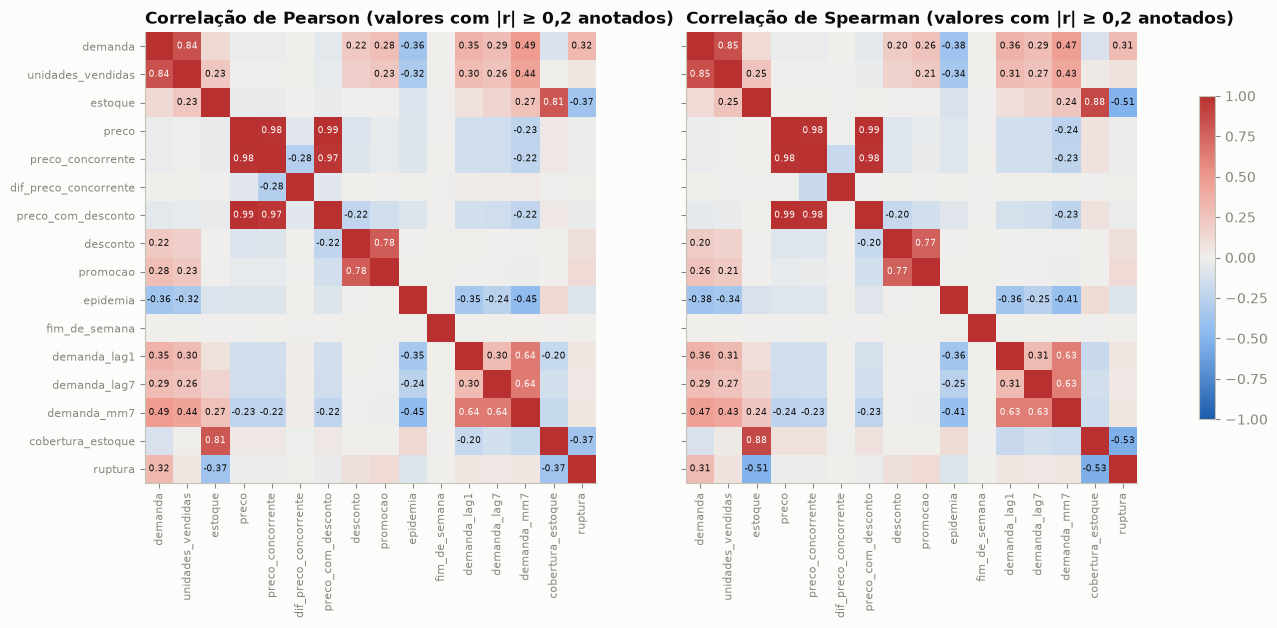

In [23]:
cols_corr = ["demanda", "unidades_vendidas", "estoque", "preco", "preco_concorrente", "dif_preco_concorrente",
             "preco_com_desconto", "desconto", "promocao", "epidemia", "fim_de_semana",
             "demanda_lag1", "demanda_lag7", "demanda_mm7", "cobertura_estoque", "ruptura"]
base_corr = df[cols_corr].dropna()
pearson = base_corr.corr("pearson")
spearman = base_corr.corr("spearman")

fig, axs = plt.subplots(1, 2, figsize=(16, 7))
for ax, m, nome in [(axs[0], pearson, "Pearson"), (axs[1], spearman, "Spearman")]:
    im = ax.imshow(m, cmap=DIVERGENTE, vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols_corr)), cols_corr, rotation=90, fontsize=8)
    ax.set_yticks(range(len(cols_corr)), cols_corr if ax is axs[0] else [], fontsize=8)
    ax.grid(False)
    for i in range(len(cols_corr)):
        for j in range(len(cols_corr)):
            v = m.iloc[i, j]
            if abs(v) >= 0.2 and i != j:
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5,
                        color="#fcfcfb" if abs(v) > 0.6 else "#0b0b0b")
    ax.set_title(f"Correlação de {nome} (valores com |r| ≥ 0,2 anotados)")
fig.colorbar(im, ax=axs, shrink=0.6)
plt.show()

In [24]:
# Correlação com a demanda + teste de significância.
# "dentro do item" tira a média de cada loja × produto antes de correlacionar,
# para não confundir diferença de nível entre itens com relação entre as variáveis.
centrado = base_corr.join(df[item]).groupby(item)[cols_corr].transform(lambda s: s - s.mean())
linhas = []
for c in cols_corr[1:]:
    r, p_r = stats.pearsonr(base_corr[c], base_corr["demanda"])
    rho, p_rho = stats.spearmanr(base_corr[c], base_corr["demanda"])
    linhas.append({"variável": c, "pearson": r, "p (pearson)": p_r, "spearman": rho, "p (spearman)": p_rho,
                   "pearson dentro do item": centrado[c].corr(centrado["demanda"])})
tab_corr = pd.DataFrame(linhas).set_index("variável")
tab_corr.sort_values("pearson", key=abs, ascending=False).style.format(
    {"pearson": "{:.3f}", "spearman": "{:.3f}", "pearson dentro do item": "{:.3f}",
     "p (pearson)": "{:.1e}", "p (spearman)": "{:.1e}"})

,pearson,p (pearson),spearman,p (spearman),pearson dentro do item
variável,,,,,
unidades_vendidas,0.836,0.0e+00,0.850,0.0e+00,0.815
demanda_mm7,0.490,0.0e+00,0.474,0.0e+00,0.353
epidemia,-0.365,0.0e+00,-0.378,0.0e+00,-0.396
demanda_lag1,0.351,0.0e+00,0.355,0.0e+00,0.237
ruptura,0.317,0.0e+00,0.312,0.0e+00,0.335
demanda_lag7,0.290,0.0e+00,0.292,0.0e+00,0.166
promocao,0.282,0.0e+00,0.261,0.0e+00,0.306
desconto,0.224,0.0e+00,0.204,0.0e+00,0.242
estoque,0.128,1.4e-271,0.119,2.2e-234,0.084


**Interpretação:**

- **`unidades_vendidas` (0,84) não pode entrar no modelo:** só se conhece depois que o dia acaba (vazamento, pesquisa de métodos seção 3).
- **Histórico:** a média móvel de 7 dias (0,49) é a variável mais correlacionada com a demanda, seguida da demanda de ontem (0,35) e da de 7 dias antes (0,29). **Dentro do item a relação cai** para 0,35, 0,24 e 0,17. Parte da correlação geral vem só de itens que vendem mais terem tudo mais alto (princípio dos resíduos). Ainda assim, o histórico ajuda.
- **Fatores externos:** epidemia (−0,37), promoção (0,28) e desconto (0,22).
- **Calendário e concorrente:** fim de semana e diferença para o concorrente ficam em zero e **são as únicas sem significância** (p de 0,23 e 0,49). Todo o resto rejeita H0, mas com 76 mil linhas até uma correlação de 0,02 vira "significativa". O que importa é o tamanho.
- **Pearson e Spearman ficam muito próximos:** as relações são parecidas com retas e não são distorcidas por extremos.
- **Para a ruptura:** as variáveis mais ligadas são o estoque (−0,37 Pearson, −0,51 Spearman) e a cobertura (−0,37 e −0,53). O Spearman maior indica relação forte, mas não linear (seção 10.2).
- **Variáveis redundantes:** preço, preço do concorrente e preço com desconto (0,97 a 0,99) e promoção com desconto (0,78). A seção 8.1 mostra um problema maior com o preço.

### 8.1 Preço e demanda: a correlação muda de sinal dentro do item

Na tabela acima, o preço quase não se relaciona com a demanda na base toda (−0,02), mas dentro do item a correlação é **+0,67**. Quando a relação muda de sinal ao separar os grupos, é um caso de paradoxo de Simpson.

Correlação preço × demanda entre itens (médias dos 100 itens): -0.51
Correlação preço × demanda dentro de cada item: mediana 0.81 | mín. 0.7 | máx. 0.86
R² do preço sobre a demanda dentro de item × nível de desconto: mediana 0.965 | mín. 0.921


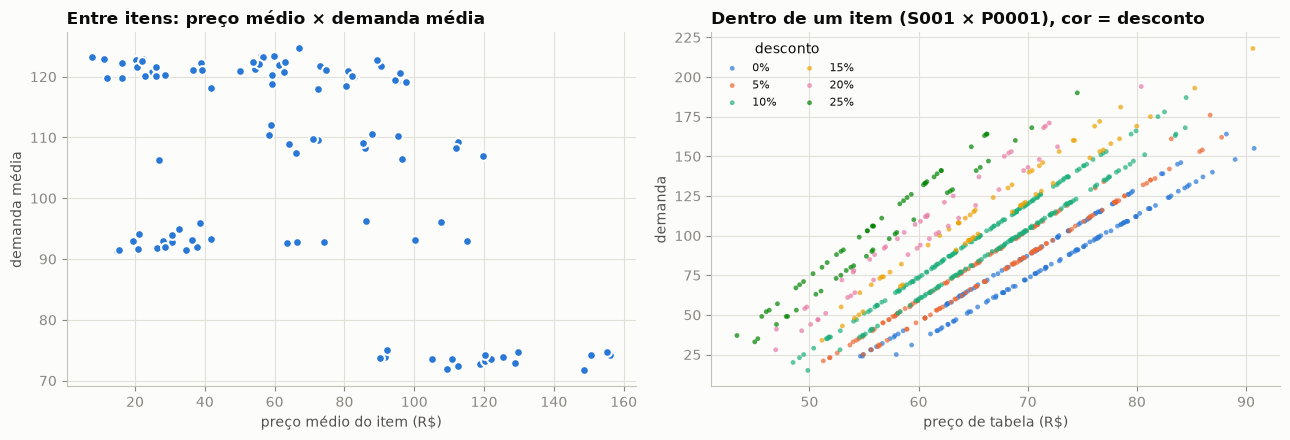

In [25]:
medias = df.groupby(item)[["preco", "demanda"]].mean()
r2 = df.groupby(item + ["desconto"])[["preco", "demanda"]].apply(lambda s: s["preco"].corr(s["demanda"]) ** 2)
r_item = df.groupby(item)[["preco", "demanda"]].apply(lambda s: s["preco"].corr(s["demanda"]))

print("Correlação preço × demanda entre itens (médias dos 100 itens):", round(medias["preco"].corr(medias["demanda"]), 2))
print("Correlação preço × demanda dentro de cada item: mediana", round(r_item.median(), 2), "| mín.", round(r_item.min(), 2), "| máx.", round(r_item.max(), 2))
print("R² do preço sobre a demanda dentro de item × nível de desconto: mediana", round(r2.median(), 3), "| mín.", round(r2.min(), 3))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].scatter(medias["preco"], medias["demanda"], s=40, color=AZUL, edgecolor="#fcfcfb", linewidth=1.5)
axs[0].set_title("Entre itens: preço médio × demanda média")
axs[0].set_xlabel("preço médio do item (R$)")
axs[0].set_ylabel("demanda média")

ex = df[(df["loja_id"] == "S001") & (df["produto_id"] == "P0001")]
for i, (desc_, sub) in enumerate(ex.groupby("desconto")):
    axs[1].scatter(sub["preco"], sub["demanda"], s=12, color=CORES[i], alpha=0.7, edgecolor="none", label=f"{desc_}%")
axs[1].set_title("Dentro de um item (S001 × P0001), cor = desconto")
axs[1].set_xlabel("preço de tabela (R$)")
axs[1].set_ylabel("demanda")
axs[1].legend(title="desconto", frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

**Interpretação:**

- **Entre itens (esquerda):** os itens mais caros vendem menos (r = −0,51). Os pontos formam faixas horizontais que correspondem às categorias.
- **Dentro de um item (direita):** o preço e a demanda andam juntos em **retas quase perfeitas**, uma para cada nível de desconto. Em todos os 100 itens, dentro de cada nível de desconto, o preço explica de 92% a 98% da variação da demanda (R² mediano de 0,965).
- Uma relação tão exata não acontece em loja real: o cliente não compra mais *porque* o preço subiu. O mais provável é que **o gerador do dataset sintético tenha calculado o preço a partir da demanda do dia** (uma espécie de precificação dinâmica). É uma das limitações do dado simulado que o plano já previa (seção 1: "os padrões podem ser mais limpos que os de uma loja real").

**Decisão para a Sprint 4: o preço do dia (`preco`, `preco_com_desconto` e `preco_concorrente`, que tem 0,98 de correlação com o preço) não entra no modelo principal de demanda.** Com ele, a regressão "leria" a demanda no preço e teria um erro artificialmente baixo, que não se repetiria com os dados da Renata. Vale treinar uma versão com preço só para mostrar esse efeito no relatório. O coeficiente do preço também não poderia ser explicado como "efeito do preço na venda", o que fere o requisito de explicabilidade.

## 9. Agrupamentos: classificação ABC e variabilidade dos itens

A curva ABC é o agrupamento clássico de estoque: separa os poucos itens que concentram a receita dos muitos que pesam pouco. Junto dela, o CV da demanda separa itens estáveis (X) de instáveis (Z). Cada item é um par loja × produto (100 itens).

In [26]:
itens = df.groupby(item).agg(
    categoria=("categoria", "first"),
    receita=("unidades_vendidas", lambda s: (s * df.loc[s.index, "preco_com_desconto"]).sum()),
    demanda_media=("demanda", "mean"),
    desvio=("demanda", "std"),
    ruptura_pct=("ruptura", "mean"),
    estoque_medio=("estoque", "mean"),
).sort_values("receita", ascending=False)
itens["estoque_dias"] = itens["estoque_medio"] / itens["demanda_media"]
itens["cv"] = itens["desvio"] / itens["demanda_media"]
itens["ruptura_pct"] *= 100

# ABC: itens que somam 80% da receita (A), os próximos 15% (B) e o resto (C)
acumulado = itens["receita"].cumsum() / itens["receita"].sum()
itens["abc"] = np.where(acumulado.shift(fill_value=0) < 0.80, "A", np.where(acumulado.shift(fill_value=0) < 0.95, "B", "C"))

# Variabilidade: terços do coeficiente de variação (X = mais estável, Z = mais instável)
itens["xyz"] = pd.qcut(itens["cv"], 3, labels=["X", "Y", "Z"]).astype(str)

pd.crosstab(itens["abc"], itens["xyz"], margins=True, margins_name="total")

xyz,X,Y,Z,total
abc,,,,
A,19,22,18,59
B,9,9,7,25
C,6,2,8,16
total,34,33,33,100


In [27]:
itens.groupby("abc").agg(itens=("receita", "size"), receita_pct=("receita", "sum"),
                        demanda_media=("demanda_media", "mean"), cv=("cv", "mean"),
                        ruptura_pct=("ruptura_pct", "mean")).assign(
    receita_pct=lambda t: (t["receita_pct"] / itens["receita"].sum() * 100)).round(2)

,itens,receita_pct,demanda_media,cv,ruptura_pct
abc,,,,,
A,59,80.01,101.84,0.41,12.33
B,25,15.35,107.88,0.42,18.09
C,16,4.64,107.90,0.44,18.36


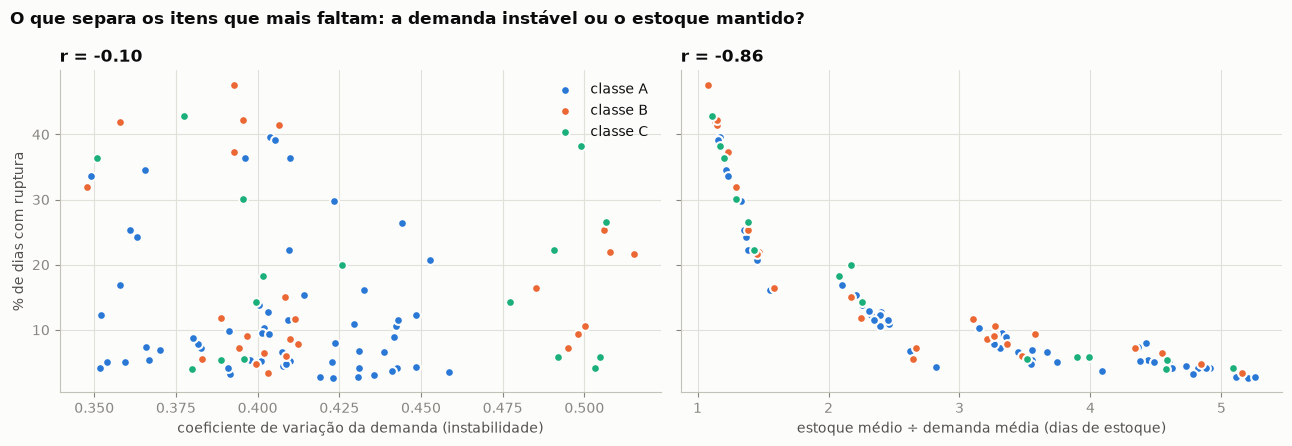

In [28]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, x, rotulo in [(axs[0], "cv", "coeficiente de variação da demanda (instabilidade)"),
                      (axs[1], "estoque_dias", "estoque médio ÷ demanda média (dias de estoque)")]:
    for i, classe in enumerate(["A", "B", "C"]):
        sub = itens[itens["abc"] == classe]
        ax.scatter(sub[x], sub["ruptura_pct"], s=40, color=CORES[i], label=f"classe {classe}",
                   edgecolor="#fcfcfb", linewidth=1.5)
    ax.set_xlabel(rotulo)
    ax.set_title(f"r = {itens[x].corr(itens['ruptura_pct']):.2f}")
axs[0].set_ylabel("% de dias com ruptura")
axs[0].legend(frameon=False)
fig.suptitle("O que separa os itens que mais faltam: a demanda instável ou o estoque mantido?", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

In [29]:
# Agrupamento pela política de estoque: terços de "dias de estoque" (pouco, médio, folgado)
itens["politica_estoque"] = pd.qcut(itens["estoque_dias"], 3, labels=["enxuto", "médio", "folgado"]).astype(str)
itens.groupby("politica_estoque").agg(itens=("receita", "size"), estoque_dias=("estoque_dias", "mean"),
                                      demanda_media=("demanda_media", "mean"), ruptura_pct=("ruptura_pct", "mean"),
                                      ruptura_min=("ruptura_pct", "min"), ruptura_max=("ruptura_pct", "max")
                                      ).loc[["enxuto", "médio", "folgado"]].round(2)

,itens,estoque_dias,demanda_media,ruptura_pct,ruptura_min,ruptura_max
politica_estoque,,,,,,
enxuto,34,1.42,106.63,29.25,15.00,47.63
médio,33,2.89,106.51,9.54,4.34,14.34
folgado,33,4.48,99.74,4.98,2.63,9.34


**Interpretação:**

- **Curva ABC achatada:** 59 dos 100 itens fazem 80% da receita. Em loja real, costuma ser algo perto de 20 itens. É mais um sinal do dado sintético, em que os itens são parecidos entre si. A instabilidade (XYZ) se espalha igualmente pelas três classes.
- **O agrupamento que de fato separa os itens é a política de estoque.** A frequência de ruptura de um item quase não depende da instabilidade da demanda (r = −0,10), mas depende muito de quantos dias de demanda o item costuma ter em estoque (r = −0,86).
  - Itens **enxutos** (~1,4 dia de estoque): ruptura em 29% dos dias, chegando a 48%.
  - Itens **folgados** (~4,5 dias): ruptura em 5% dos dias.
  - A demanda média dos três grupos é parecida (100 a 107).
- **O problema da ruptura é de reposição, não de demanda imprevisível.** É exatamente o que o StockFlow quer resolver: ajustar quanto e quando repor. As classes B e C têm mais ruptura (18%) que a A (12%), ou seja, os itens que pesam menos na receita são os mais negligenciados no estoque.

## 10. Análises estatísticas e probabilísticas

### 10.1 Distribuição da demanda diária

Qual distribuição descreve a demanda diária de um item? A resposta importa para o estoque de segurança (pesquisa de métodos, seção 6), que supõe erros normais. Comparação por AIC (critério de informação de Akaike: menor é melhor) entre normal, Poisson e binomial negativa, ajustadas em cada um dos 100 itens.

In [30]:
def ajuste(y):
    """Log-verossimilhança e AIC de três distribuições para a demanda diária de um item."""
    y = y.to_numpy()
    m, v = y.mean(), y.var(ddof=1)
    res = {}
    ll = stats.norm.logpdf(y, m, np.sqrt(v)).sum()
    res["normal"] = 2 * 2 - 2 * ll
    ll = stats.poisson.logpmf(y, m).sum()
    res["poisson"] = 2 * 1 - 2 * ll
    # binomial negativa pelos momentos (exige variância > média)
    p = m / v
    r = m * p / (1 - p)
    ll = stats.nbinom.logpmf(y, r, p).sum()
    res["binomial negativa"] = 2 * 2 - 2 * ll
    return pd.Series(res)

aic = df.groupby(item)["demanda"].apply(ajuste).unstack()
disp = df.groupby(item)["demanda"].agg(lambda s: s.var() / s.mean())

print("Variância / média da demanda por item (Poisson exige ≈ 1):")
print(disp.describe().round(1).to_string())
print()
print("Distribuição com menor AIC, em quantos itens:")
print(aic.idxmin(axis=1).value_counts().to_string())
print()
print("AIC médio por distribuição (menor = melhor):")
print(aic.mean().round(0).to_string())

Variância / média da demanda por item (Poisson exige ≈ 1):
count    100.0
mean      17.8
std        3.2
min       13.1
25%       14.6
50%       18.4
75%       19.7
max       24.3

Distribuição com menor AIC, em quantos itens:
binomial negativa    69
normal               31

AIC médio por distribuição (menor = melhor):
normal                7856.0
poisson              18682.0
binomial negativa     7846.0


**Interpretação:**

- **Poisson é descartada:** ela exige variância igual à média, mas a variância da demanda é de 13 a 24 vezes a média (sobredispersão). O AIC da Poisson é mais que o dobro do das outras duas.
- **Binomial negativa e normal empatam na prática:** a binomial negativa ganha em 69 itens, mas o AIC médio difere só 0,1% (7.846 contra 7.856). A binomial negativa é a distribuição natural para contagens com sobredispersão. A normal, porém, descreve a demanda quase tão bem e é a que a fórmula do estoque de segurança usa. O gráfico abaixo verifica o que a fórmula realmente precisa: a forma do **erro** (resíduo), e não da demanda bruta.

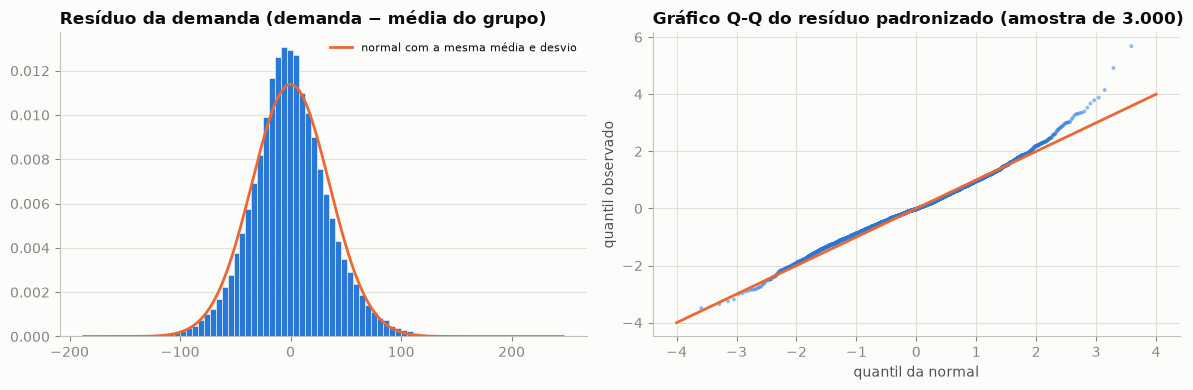

Assimetria: 0.2 | Curtose (normal = 0): 0.97
P(resíduo ≤ 1.28·σ): observado 90.4% | normal 90.0% (nível de serviço 90%)
P(resíduo ≤ 1.65·σ): observado 94.6% | normal 95.1% (nível de serviço 95%)
P(resíduo ≤ 2.33·σ): observado 98.3% | normal 99.0% (nível de serviço 99%)


In [31]:
# O estoque de segurança usa o erro da previsão, não a demanda bruta (pesquisa, seção 6).
# Aproximação do erro de um modelo simples: demanda menos a média do item na mesma estação,
# com e sem promoção e epidemia.
grupo_res = item + ["estacao", "promocao", "epidemia"]
df["residuo_simples"] = df["demanda"] - df.groupby(grupo_res)["demanda"].transform("mean")
res = df["residuo_simples"]
res_pad = (res - res.mean()) / res.std()

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].hist(res, bins=80, color=AZUL, edgecolor="#fcfcfb", linewidth=0.4, density=True)
x = np.linspace(res.min(), res.max(), 300)
axs[0].plot(x, stats.norm.pdf(x, res.mean(), res.std()), color=LARANJA, label="normal com a mesma média e desvio")
axs[0].set_title("Resíduo da demanda (demanda − média do grupo)")
axs[0].legend(frameon=False, fontsize=8)
axs[0].grid(axis="x", visible=False)

amostra = res_pad.sample(3000, random_state=42).sort_values()
teoricos = stats.norm.ppf((np.arange(1, len(amostra) + 1) - 0.5) / len(amostra))
axs[1].scatter(teoricos, amostra, s=8, color=AZUL, alpha=0.5, edgecolor="none")
axs[1].plot([-4, 4], [-4, 4], color=LARANJA)
axs[1].set_title("Gráfico Q-Q do resíduo padronizado (amostra de 3.000)")
axs[1].set_xlabel("quantil da normal")
axs[1].set_ylabel("quantil observado")
plt.tight_layout()
plt.show()

print("Assimetria:", round(res.skew(), 2), "| Curtose (normal = 0):", round(res.kurt(), 2))
for z, nivel in [(1.28, "90%"), (1.65, "95%"), (2.33, "99%")]:
    print(f"P(resíduo ≤ {z}·σ): observado {(res_pad <= z).mean():.1%} | normal {stats.norm.cdf(z):.1%} (nível de serviço {nivel})")

**Interpretação (resíduos):**

- Depois de tirar o efeito do item, da estação, da promoção e da epidemia, o que sobra é quase simétrico (assimetria 0,2), mas tem caudas um pouco mais pesadas que a normal (curtose 0,97). No gráfico Q-Q, os pontos seguem a reta até cerca de 2 desvios e se afastam para cima na cauda direita: dias de demanda muito acima do esperado são mais comuns do que a normal prevê.
- Na prática, para o estoque de segurança (z × σ × √L):
  - **90% e 95% de nível de serviço:** a normal acerta (90,4% e 94,6% observados contra 90,0% e 95,1% teóricos). O z = 1,65 da pesquisa de métodos pode ser usado.
  - **99%:** a normal promete 99,0% e entrega 98,3%. Para níveis tão altos, é melhor usar o quantil observado do erro do modelo, em vez do z tabelado.

A confirmação final é na análise de resíduos do modelo da Sprint 4.

### 10.2 Probabilidade de ruptura

Probabilidade geral e condicional, com intervalo de confiança de 95% de Wilson (mais preciso que a aproximação normal para proporções).

In [32]:
def prob_ruptura(base, grupo):
    t = base.groupby(grupo)["ruptura"].agg(rupturas="sum", dias="count")
    t["P(ruptura)"] = t["rupturas"] / t["dias"]
    ic = proportion_confint(t["rupturas"], t["dias"], alpha=0.05, method="wilson")
    t["IC 95% inf"], t["IC 95% sup"] = ic
    return t

total = df["ruptura"].sum()
ic = proportion_confint(total, len(df), method="wilson")
print(f"P(ruptura) geral: {total / len(df):.2%}  (IC 95%: {ic[0]:.2%} a {ic[1]:.2%})")
print("Referência da Matriz CSD (taxa média mundial): 8,3%")

P(ruptura) geral: 14.74%  (IC 95%: 14.49% a 14.99%)
Referência da Matriz CSD (taxa média mundial): 8,3%


In [33]:
condicionais = pd.concat({
    "categoria": prob_ruptura(df, "categoria"),
    "clima": prob_ruptura(df, "clima"),
    "promocao": prob_ruptura(df, "promocao"),
    "epidemia": prob_ruptura(df, "epidemia"),
    "desconto": prob_ruptura(df, "desconto"),
    "fim_de_semana": prob_ruptura(df, "fim_de_semana"),
})
condicionais.style.format({"P(ruptura)": "{:.1%}", "IC 95% inf": "{:.1%}", "IC 95% sup": "{:.1%}"})

**Interpretação:**

- **Taxa geral:** P(ruptura) = 14,7% (IC 95%: 14,5% a 15,0%). É quase o dobro da taxa média mundial de 8,3% da Matriz CSD: o cenário simulado tem mais ruptura do que o varejo real costuma ter, o que reforça a utilidade do alerta.
- **Promoção quase dobra o risco:** 20,8% com promoção contra 11,8% sem. Os descontos de 15% a 25% (que só existem em promoção) ficam todos em torno de 20%. **A promoção aumenta a demanda, mas o estoque não acompanha.**
- **Clima:** sol tem mais ruptura (18,0%) que chuva ou neve (~12%), seguindo a demanda.
- **Epidemia:** tem metade da ruptura (8,3% contra 16,3%), porque a demanda cai e o estoque sobra.
- **Categoria:** Clothing (20,9%) contra Furniture (8,5%).
- **Fim de semana:** igual ao dia útil, com os intervalos sobrepostos.
- **Mesma direção da demanda:** onde a demanda sobe, a ruptura sobe junto. Para a Renata, isso vira um aviso prático: **ao programar uma promoção, reforçar o estoque antes.**

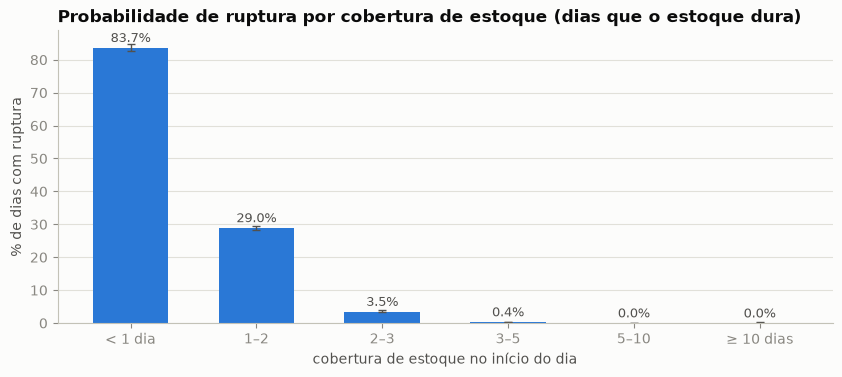

,rupturas,dias,P(ruptura),IC 95% inf,IC 95% sup,% dos dias
faixa,,,,,,
< 1 dia,4367,5218,83.7%,82.7%,84.7%,6.9
1–2,6092,21043,29.0%,28.3%,29.6%,27.9
2–3,484,13815,3.5%,3.2%,3.8%,18.3
3–5,63,17858,0.4%,0.3%,0.5%,23.7
5–10,4,15386,0.0%,0.0%,0.1%,20.4
≥ 10 dias,0,1980,0.0%,0.0%,0.2%,2.6


In [34]:
faixas_cob = pd.cut(df["cobertura_estoque"], [0, 1, 2, 3, 5, 10, np.inf], right=False,
                    labels=["< 1 dia", "1–2", "2–3", "3–5", "5–10", "≥ 10 dias"])
tab_cob = prob_ruptura(df.assign(faixa=faixas_cob), "faixa")
tab_cob["% dos dias"] = tab_cob["dias"] / tab_cob["dias"].sum() * 100

fig, ax = plt.subplots(figsize=(10, 3.8))
erro = [tab_cob["P(ruptura)"] - tab_cob["IC 95% inf"], tab_cob["IC 95% sup"] - tab_cob["P(ruptura)"]]
ax.bar(tab_cob.index.astype(str), tab_cob["P(ruptura)"] * 100, yerr=np.array(erro) * 100, color=AZUL, width=0.6,
       capsize=3, error_kw={"ecolor": "#52514e", "elinewidth": 1})
for x, v in zip(tab_cob.index.astype(str), tab_cob["P(ruptura)"] * 100):
    ax.annotate(f"{v:.1f}%", (x, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, color="#52514e")
ax.set_title("Probabilidade de ruptura por cobertura de estoque (dias que o estoque dura)")
ax.set_ylabel("% de dias com ruptura")
ax.set_xlabel("cobertura de estoque no início do dia")
ax.grid(axis="x", visible=False)
plt.show()
tab_cob.style.format({"P(ruptura)": "{:.1%}", "IC 95% inf": "{:.1%}", "IC 95% sup": "{:.1%}", "% dos dias": "{:.1f}"})

**Interpretação:** a cobertura de estoque é, de longe, o melhor indicador de ruptura.

| Cobertura no início do dia | P(ruptura) | % dos dias |
|---|---|---|
| menos de 1 dia | 84% | 7% |
| 1 a 2 dias | 29% | 28% |
| 2 a 3 dias | 3,5% | — |
| 3 dias ou mais | praticamente zero | — |

- **Os dias com menos de 2 dias de cobertura** são 35% do total e concentram **95% das rupturas** (10.459 de 11.010; outras 190 caem nos primeiros 7 dias de cada item, que não têm cobertura).
- **A probabilidade cai como uma escada**, e não em linha reta. Por isso a correlação de Spearman (−0,53) é maior que a de Pearson (−0,37).
- **Consequências para a Sprint 4:**
  - a cobertura deve ser a variável central do classificador;
  - uma regra simples de "alerta quando a cobertura for menor que 2 dias" já é uma referência forte, que o modelo precisa superar, como as previsões de referência da regressão;
  - para o dashboard, a faixa de cobertura vira a cor do alerta (seção 7 do plano).

### 10.3 Testes de hipótese

H0 em todos: não há diferença entre os grupos (ou não há associação). Com 76 mil linhas, qualquer diferença mínima vira "significativa", por isso cada teste vem com o **tamanho do efeito**, que é o que diz se a diferença importa:

- d de Cohen: 0,2 pequeno, 0,5 médio, 0,8 grande;
- η²: 0,01 pequeno, 0,06 médio, 0,14 grande;
- V de Cramér: 0,1 pequeno, 0,3 médio, 0,5 grande.

A comparação de fim de semana é feita com a média de cada dia (760 dias), porque as 100 linhas de um mesmo dia não são independentes entre si.

In [35]:
def cramer_v(tabela):
    chi2 = stats.chi2_contingency(tabela)[0]
    n = tabela.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(tabela.shape) - 1)))

testes = []

# (a) Fim de semana × dia útil — no nível do dia (760 dias), para as observações serem independentes
dia = df.groupby("data").agg(demanda=("demanda", "mean"), fim_de_semana=("fim_de_semana", "first"),
                              estacao=("estacao", "first"), epidemia=("epidemia", "first"))
a, b = dia.loc[dia["fim_de_semana"] == 1, "demanda"], dia.loc[dia["fim_de_semana"] == 0, "demanda"]
t, p_t = stats.ttest_ind(a, b, equal_var=False)
u, p_u = stats.mannwhitneyu(a, b)
d_cohen = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
testes.append(["Demanda: fim de semana × dia útil", "t de Welch", p_t, f"d de Cohen = {d_cohen:.2f}"])
testes.append(["Demanda: fim de semana × dia útil", "Mann-Whitney", p_u, f"médias {a.mean():.1f} × {b.mean():.1f}"])

# (b) Promoção — nas linhas (item × dia)
a, b = df.loc[df["promocao"] == 1, "demanda"], df.loc[df["promocao"] == 0, "demanda"]
t, p_t = stats.ttest_ind(a, b, equal_var=False)
d_cohen = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
testes.append(["Demanda: com × sem promoção", "t de Welch", p_t, f"d de Cohen = {d_cohen:.2f}"])

# (c) Clima e estação — mais de dois grupos
for col, base in [("clima", df), ("estacao", sem_epi)]:
    grupos = [s.to_numpy() for _, s in base.groupby(col)["demanda"]]
    f, p_f = stats.f_oneway(*grupos)
    h, p_h = stats.kruskal(*grupos)
    nome = "Demanda entre climas" if col == "clima" else "Demanda entre estações (sem epidemia)"
    testes.append([nome, "ANOVA", p_f, f"η² = {eta2(base['demanda'], base[col]):.3f}"])
    testes.append([nome, "Kruskal-Wallis", p_h, f"H = {h:.0f}"])

# (d) Ruptura × categóricas — qui-quadrado
for col in ["categoria", "clima", "promocao", "epidemia", "fim_de_semana"]:
    tab = pd.crosstab(df[col], df["ruptura"])
    chi2, p_c, gl, _ = stats.chi2_contingency(tab)
    testes.append([f"Ruptura × {col}", "qui-quadrado", p_c, f"V de Cramér = {cramer_v(tab):.3f}"])

tab_testes = pd.DataFrame(testes, columns=["pergunta", "teste", "p-valor", "tamanho do efeito"])
tab_testes["rejeita H0 (5%)"] = np.where(tab_testes["p-valor"] < 0.05, "sim", "não")
tab_testes.style.format({"p-valor": "{:.2e}"})

,pergunta,teste,p-valor,tamanho do efeito,rejeita H0 (5%)
0,Demanda: fim de semana × dia útil,t de Welch,8.15e-01,d de Cohen = 0.02,não
1,Demanda: fim de semana × dia útil,Mann-Whitney,6.05e-01,médias 104.6 × 104.2,não
2,Demanda: com × sem promoção,t de Welch,0.00e+00,d de Cohen = 0.60,sim
3,Demanda entre climas,ANOVA,0.00e+00,η² = 0.032,sim
4,Demanda entre climas,Kruskal-Wallis,0.00e+00,H = 2227,sim
5,Demanda entre estações (sem epidemia),ANOVA,2.18e-131,η² = 0.010,sim
6,Demanda entre estações (sem epidemia),Kruskal-Wallis,1.94e-89,H = 414,sim
7,Ruptura × categoria,qui-quadrado,3.55e-174,V de Cramér = 0.103,sim
8,Ruptura × clima,qui-quadrado,7.97e-85,V de Cramér = 0.072,sim
9,Ruptura × promocao,qui-quadrado,1.90e-235,V de Cramér = 0.119,sim


**Interpretação:**

- **Fim de semana não muda a demanda:** p = 0,82 no teste t e 0,61 no Mann-Whitney, com d de Cohen de 0,02. Não se rejeita H0. Também não muda a ruptura (V de Cramér de 0,007, p = 0,06).
- **Promoção tem efeito médio** (d = 0,60), o maior entre os fatores testados.
- **Clima (η² = 0,032) e estação (η² = 0,010)** são significativos, mas com efeito pequeno: cada um explica entre 1% e 3% da variação da demanda. Ajudam, mas não sustentam um modelo sozinhos.
- **Ruptura × categóricas:** todas as associações são significativas, mas fracas (V entre 0,07 e 0,12). Nenhuma variável categórica sozinha prevê a ruptura; o que prevê é a cobertura (seção 10.2).
- **Testes paramétricos e não paramétricos concordam** (t × Mann-Whitney, ANOVA × Kruskal-Wallis). Os resultados não dependem da suposição de normalidade.

**Conclusão dos testes:** para a demanda, o que tem efeito relevante é **epidemia, promoção, clima e estação**, além do histórico. Calendário semanal fica fora.

## 11. Valores extremos (outliers)

### 11.1 Univariados

A Silver já marcou os extremos por IQR dentro de cada loja × produto (log, etapa 8). Aqui se avalia **onde** eles aparecem e se o critério do IQR concorda com o do escore z.

In [36]:
extremos = ["extremo_unidades_vendidas", "extremo_demanda", "extremo_estoque", "extremo_preco"]
uni = pd.DataFrame({
    "% geral": df[extremos].mean() * 100,
    "% com promoção": df.loc[df["promocao"] == 1, extremos].mean() * 100,
    "% sem promoção": df.loc[df["promocao"] == 0, extremos].mean() * 100,
    "% na epidemia": df.loc[df["epidemia"] == 1, extremos].mean() * 100,
    "% com ruptura": df.loc[df["ruptura"] == 1, extremos].mean() * 100,
}).round(2)

# Comparação com o critério |z| > 3 dentro do item
z = df.groupby(item)["demanda"].transform(lambda s: (s - s.mean()) / s.std())
print("Extremos de demanda — IQR:", df["extremo_demanda"].sum(), "| |z| > 3:", int((z.abs() > 3).sum()),
      "| nos dois:", int(((z.abs() > 3) & (df["extremo_demanda"] == 1)).sum()))
uni

Extremos de demanda — IQR: 804 | |z| > 3: 403 | nos dois: 403


,% geral,% com promoção,% sem promoção,% na epidemia,% com ruptura
extremo_unidades_vendidas,1.45,3.45,0.47,0.28,1.57
extremo_demanda,1.06,2.90,0.15,0.29,3.53
extremo_estoque,1.47,1.36,1.53,0.44,0.03
extremo_preco,0.72,1.03,0.57,0.31,2.02


In [37]:
# Os extremos de demanda são altos ou baixos?
lado = np.where(z > 0, "acima", "abaixo")
pd.crosstab(df.loc[df["extremo_demanda"] == 1, "categoria"], lado[df["extremo_demanda"] == 1])

col_0,abaixo,acima
categoria,,
Clothing,13,172
Electronics,0,74
Furniture,0,95
Groceries,0,389
Toys,0,61


**Interpretação:**

- **Os dois critérios concordam:** os 403 extremos de demanda pelo escore z (|z| > 3) estão todos entre os 804 do IQR. O IQR é mais rigoroso e marca também os casos menos extremos.
- **Quase todos os extremos de demanda estão acima do normal** (791 de 804) e se concentram na promoção: 2,9% dos dias com promoção contra 0,15% sem. Na epidemia quase não há (0,3%). São **picos reais de venda**, e não erros de registro.
- **Os extremos de estoque se comportam diferente:** não dependem da promoção e quase nunca ocorrem em dia de ruptura (0,03%). São estoques muito altos, que indicam excesso de mercadoria, o outro problema que o StockFlow quer evitar.
- **Decisão:** manter todos, só com a marcação, como o plano define (seção 4). Remover os picos de promoção tiraria do modelo justamente os dias em que a ruptura é mais provável.

### 11.2 Bivariados

Um ponto pode ser normal em cada variável sozinha e estranho na combinação (ex.: preço alto com demanda alta). Critério: distância de Mahalanobis dentro de cada item, com limite no quantil 99,9% da qui-quadrado com 2 graus de liberdade. Pares avaliados: preço pago × demanda e estoque × demanda. Os pontos são **marcados**, não removidos, seguindo a seção 4 do plano.

In [38]:
limite = stats.chi2.ppf(0.999, df=2)

def mahalanobis(sub, x, y):
    v = sub[[x, y]].to_numpy(dtype=float)
    dif = v - v.mean(axis=0)
    inv = np.linalg.inv(np.cov(v, rowvar=False))
    return np.einsum("ij,jk,ik->i", dif, inv, dif)

pares = [("preco_com_desconto", "demanda"), ("estoque", "demanda")]
for x, y in pares:
    d2 = pd.concat([pd.Series(mahalanobis(s, x, y), index=s.index) for _, s in df.groupby(item)])
    df[f"extremo_biv_{x}"] = (d2.reindex(df.index) > limite).astype("int64")

biv = pd.DataFrame({
    "extremos": [df[f"extremo_biv_{x}"].sum() for x, _ in pares],
    "% das linhas": [df[f"extremo_biv_{x}"].mean() * 100 for x, _ in pares],
    "% também extremo univariado de demanda": [
        df.loc[df[f"extremo_biv_{x}"] == 1, "extremo_demanda"].mean() * 100 for x, _ in pares],
    "% com promoção": [df.loc[df[f"extremo_biv_{x}"] == 1, "promocao"].mean() * 100 for x, _ in pares],
}, index=[f"{x} × {y}" for x, y in pares]).round(2)
biv

,extremos,% das linhas,% também extremo univariado de demanda,% com promoção
preco_com_desconto × demanda,178,0.23,98.88,91.01
estoque × demanda,365,0.48,44.66,58.36


In [39]:
# Direção dos extremos de estoque × demanda (acima ou abaixo da média do item)
sel = df["extremo_biv_estoque"] == 1
media_item = df.groupby(item)[["estoque", "demanda"]].transform("mean")
pd.crosstab(np.where(df.loc[sel, "estoque"] > media_item.loc[sel, "estoque"], "estoque alto", "estoque baixo"),
            np.where(df.loc[sel, "demanda"] > media_item.loc[sel, "demanda"], "demanda alta", "demanda baixa"))

col_0,demanda alta,demanda baixa
row_0,,
estoque alto,206,90
estoque baixo,69,0


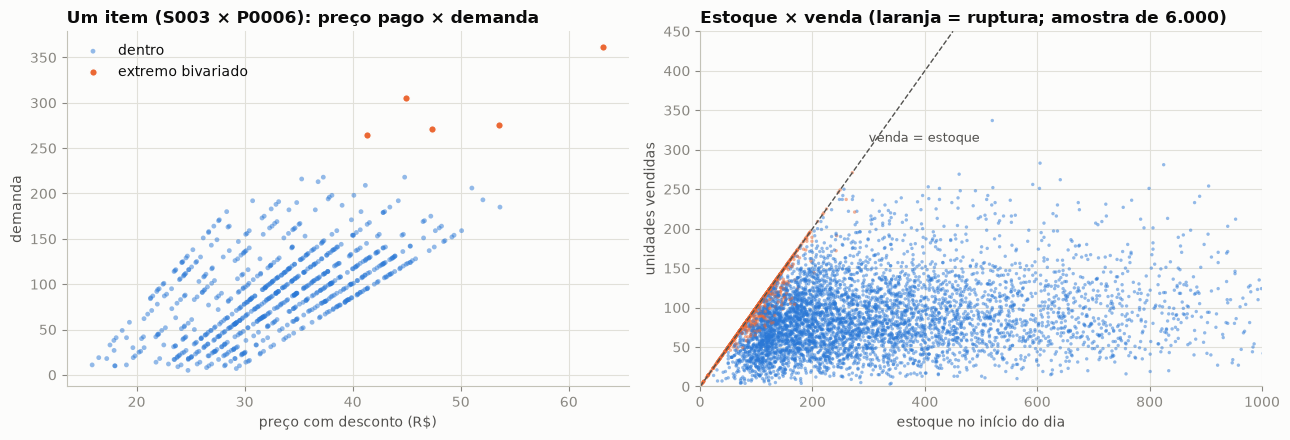

In [40]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
# Item com mais extremos bivariados de preço × demanda
loja_ex, prod_ex = df.groupby(item)["extremo_biv_preco_com_desconto"].sum().idxmax()
ex = df[(df["loja_id"] == loja_ex) & (df["produto_id"] == prod_ex)]
normal = ex[ex["extremo_biv_preco_com_desconto"] == 0]
fora = ex[ex["extremo_biv_preco_com_desconto"] == 1]
axs[0].scatter(normal["preco_com_desconto"], normal["demanda"], s=12, color=AZUL, alpha=0.5, edgecolor="none", label="dentro")
axs[0].scatter(fora["preco_com_desconto"], fora["demanda"], s=30, color=LARANJA, edgecolor="#fcfcfb", label="extremo bivariado")
axs[0].set_title(f"Um item ({loja_ex} × {prod_ex}): preço pago × demanda")
axs[0].set_xlabel("preço com desconto (R$)")
axs[0].set_ylabel("demanda")
axs[0].legend(frameon=False)

amostra = df.sample(6000, random_state=1)
cor = np.where(amostra["ruptura"] == 1, LARANJA, AZUL)
axs[1].scatter(amostra["estoque"], amostra["unidades_vendidas"], s=6, c=cor, alpha=0.5, edgecolor="none")
lim = 450
axs[1].plot([0, lim], [0, lim], color="#52514e", linewidth=1, linestyle="--")
axs[1].annotate("venda = estoque", (300, 310), color="#52514e", fontsize=9)
axs[1].set_xlim(0, 1000)
axs[1].set_ylim(0, lim)
axs[1].set_title("Estoque × venda (laranja = ruptura; amostra de 6.000)")
axs[1].set_xlabel("estoque no início do dia")
axs[1].set_ylabel("unidades vendidas")
plt.tight_layout()
plt.show()

**Interpretação:**

- **Preço pago × demanda:** os 178 extremos bivariados (0,23%) são todos dias de demanda acima da média do item. Em 99% dos casos já eram extremos univariados de demanda, e 91% estão em promoção. No gráfico da esquerda, ficam bem acima das retas: dias em que a demanda passou muito do que o preço do dia indicaria, que são os picos de promoção. Não revelam nenhum caso novo.
- **Estoque × demanda:** 365 casos (0,48%), e menos da metade já era extremo univariado. Há três tipos:
  - estoque e demanda altos ao mesmo tempo (206), em que a loja estava abastecida num dia forte;
  - estoque alto com demanda baixa (90), que é **excesso de mercadoria**;
  - estoque baixo com demanda alta (69), que é o **cenário de ruptura**.

  São combinações raras, mas coerentes com o negócio, e não erros.
- **Estoque × venda (direita):** nenhum ponto passa da diagonal. **A venda nunca supera o estoque**, e os dias de ruptura (laranja) ficam todos colados na linha venda = estoque ou logo abaixo dela. É a venda censurada vista no gráfico: nesses dias a venda mostra o estoque, não a demanda.
- **Decisão:** os extremos bivariados também ficam marcados (`extremo_biv_preco_com_desconto` e `extremo_biv_estoque`) e nenhum é removido.

## 12. Preparação adicional necessária

In [41]:
# Contagem dos pontos que exigem preparação adicional
print("Linhas sem defasagem de 7 dias ou média móvel (primeiros 7 dias de cada item):", int(df["demanda_mm7"].isna().sum()))
print("Linhas com venda maior que a demanda (flag da Silver):", int(df["flag_venda_maior_demanda"].sum()))
print("Linhas no período de epidemia:", int(df["epidemia"].sum()))

Linhas sem defasagem de 7 dias ou média móvel (primeiros 7 dias de cada item): 700
Linhas com venda maior que a demanda (flag da Silver): 21000
Linhas no período de epidemia: 15200


In [42]:
# Evidências para o alvo da regressão: demanda × unidades_vendidas
sem_rup = df[df["ruptura"] == 0]
pd.DataFrame({
    "demanda": [df[c].corr(df["demanda"]) for c in ["promocao", "desconto", "epidemia"]]
               + [df["demanda"].skew(), sem_rup["demanda"].corr(sem_rup["unidades_vendidas"])],
    "unidades_vendidas": [df[c].corr(df["unidades_vendidas"]) for c in ["promocao", "desconto", "epidemia"]]
                         + [df["unidades_vendidas"].skew(), np.nan],
}, index=["correlação com promoção", "correlação com desconto", "correlação com epidemia",
          "assimetria", "correlação entre as duas nos dias sem ruptura"]).round(3)

,demanda,unidades_vendidas
correlação com promoção,0.283,0.227
correlação com desconto,0.225,0.184
correlação com epidemia,-0.364,-0.318
assimetria,0.608,0.790
correlação entre as duas nos dias sem ruptura,0.906,NaN


**Interpretação (alvo):** a `demanda` se relaciona mais com os fatores externos que a venda (promoção 0,28 contra 0,23; epidemia −0,36 contra −0,32), é menos assimétrica (0,61 contra 0,79) e não é censurada pelo estoque. Nos dias sem ruptura, as duas têm correlação de 0,91: a inconsistência de 27,6% da coluna é um ruído em torno da venda, e não uma coluna sem relação com ela.

### Decisões e preparação para a Gold de modelos (Sprints 4 a 6)

| Ponto | Decisão | Base |
|---|---|---|
| Alvo da regressão | `demanda`, mantendo `flag_venda_maior_demanda`. Comparação com a alternativa do plano (venda sem os dias de ruptura) como teste de robustez. | Tabela acima; seção 3 do plano |
| Regra da ruptura | Venda ≥ estoque **ou** demanda > estoque (14,7%) | Seção 2.5 |
| Estação × mês | `estacao` nos modelos; `mes` só para análise e filtros | Seção 6 |
| Log no alvo | Não aplicar | Seção 4 |
| Calendário semanal | `dia_semana` e `fim_de_semana` fora dos modelos | Seções 5 e 10.3 |
| Preço do dia | `preco`, `preco_com_desconto` e `preco_concorrente` fora do modelo principal de demanda; testar uma versão com preço só para mostrar o efeito | Seção 8.1 |
| Promoção × desconto | Usar `promocao`; `desconto` não acrescenta efeito além dela | Seção 7 |
| Diferença para o concorrente | Testar; sai se não reduzir o erro | Seções 7 e 8 |
| Primeiros 7 dias de cada item | Excluir dos modelos (700 linhas, 0,9%): sem defasagem e sem cobertura | Seção 2.2 |
| Valores extremos | Manter todos, marcados (univariados e bivariados) | Seção 11 |
| Epidemia | Manter como variável e testar com e sem o período, como o plano prevê | Seções 5 e 7 |
| Variável central da classificação | `cobertura_estoque`; regra "cobertura < 2 dias" como referência a superar | Seção 10.2 |
| Estoque de segurança | Normal com z = 1,65 (95%); para 99%, usar o quantil observado do erro | Seção 10.1 |

One-hot (`categoria`, `clima`, `estacao`), padronização calculada só no treino e divisão treino/teste por data continuam na Gold de modelos, como o plano define.

## 13. Salvar em `data/gold/vendas_analise.parquet`

In [43]:
df = df.drop(columns=["residuo_simples"])
df = df.sort_values(["data", "loja_id", "produto_id"]).reset_index(drop=True)
os.makedirs("data/gold", exist_ok=True)
df.to_parquet("data/gold/vendas_analise.parquet", index=False)

conferencia = pd.read_parquet("data/gold/vendas_analise.parquet")
print("Salvo:", conferencia.shape)
print("Chave data × loja × produto repetida:", conferencia.duplicated(subset=["data", "loja_id", "produto_id"]).sum())
conferencia.dtypes

Salvo: (76000, 37)
Chave data × loja × produto repetida: 0


data                              datetime64[us]
loja_id                                   string
produto_id                                string
categoria                                 string
regiao                                    string
estoque                                    int64
unidades_vendidas                          int64
unidades_pedidas                           int64
preco                                    float64
desconto                                   int64
clima                                     string
promocao                                   int64
preco_concorrente                        float64
estacao                                   string
epidemia                                   int64
demanda                                    int64
flag_venda_maior_demanda                   int64
extremo_unidades_vendidas                  int64
extremo_demanda                            int64
extremo_estoque                            int64
extremo_preco       

## 14. Principais insights (para a etapa de explanação)

1. **A ruptura é um problema de reposição, não de demanda imprevisível.** Os itens com pouco estoque em relação à demanda faltam em até 48% dos dias; os com estoque folgado, em 5%. A instabilidade da demanda quase não importa (r = −0,10).
2. **A cobertura de estoque antecipa a ruptura.** Com menos de 1 dia de cobertura, a ruptura acontece em 84% dos casos. Abaixo de 2 dias estão 95% das rupturas. É o alerta mais simples e mais forte para o dashboard da Renata.
3. **Promoção aumenta a demanda em 30% e quase dobra o risco de ruptura** (de 12% para 21%). O tamanho do desconto não muda nada: o que importa é ter promoção. Recomendação prática: reforçar o estoque antes de uma promoção.
4. **A epidemia é o fator externo mais forte** (−38% na demanda). Clima e estação têm efeito pequeno, mas real. O dia da semana não tem efeito.
5. **O preço do dia não pode ser usado para prever a demanda nesta base:** ele acompanha a demanda de forma quase exata, um artefato do dado sintético.
6. **O erro de uma previsão simples é aproximadamente normal**, o que valida a fórmula do estoque de segurança até 95% de nível de serviço.